# Single-atom Cooling (to the motional ground state)

Python companion to the AMO Toolkit page [Single-atom Cooling (to the motional ground state)](https://amotoolkit.com/pages/laser-cooling.html). It reproduces the page's calculator with the same constants and formulas, so you can change anything, script a scan, or check a number in your own analysis.

[Open in Colab](https://colab.research.google.com/github/saumitraphatak/amo-career/blob/main/notebooks/laser-cooling.ipynb) · needs only `numpy`, `scipy` and `matplotlib`.

## 1. The Lamb–Dicke parameter
$\eta = k x_0$ with $x_0 = \sqrt{\hbar/2m\omega}$, and $\eta^2 = E_r/\hbar\omega$. Below η ≈ 0.1 the carrier dominates and sidebands are weak; above 0.3 ground-state cooling gets hard. The page's constants are rounded to four or five figures.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
HBAR, AMU, KB = 1.0546e-34, 1.6605e-27, 1.3806e-23

def lamb_dicke(mass_u=87, nu_kHz=100, lam_nm=780):
    m, w, k = mass_u * AMU, 2 * np.pi * nu_kHz * 1e3, 2 * np.pi / (lam_nm * 1e-9)
    x0 = np.sqrt(HBAR / (2 * m * w))
    Er = HBAR**2 * k**2 / (2 * m)
    return dict(x0_nm=x0 * 1e9, eta=k * x0, Er_over_hnu=Er / (2 * np.pi * HBAR * nu_kHz * 1e3))

ld = lamb_dicke()
print(ld)
for name, m_u, lam in (("⁶Li, 671 nm", 6, 671), ("⁸⁷Rb, 780 nm", 87, 780), ("¹³³Cs, 852 nm", 133, 852)):
    print(f"{name:>14}: η at 100 kHz = {lamb_dicke(m_u, 100, lam)['eta']:.3f}")

{'x0_nm': np.float64(24.102377553671825), 'eta': np.float64(0.19415346732477673), 'Er_over_hnu': 0.03769556887423315}
   ⁶Li, 671 nm: η at 100 kHz = 0.859
  ⁸⁷Rb, 780 nm: η at 100 kHz = 0.194
 ¹³³Cs, 852 nm: η at 100 kHz = 0.144

## 2. Sideband cooling limits
From Phatak et al., [Phys. Rev. A 110, 043116 (2024)](https://doi.org/10.1103/PhysRevA.110.043116), Eq. 38, with α the emission-pattern factor:

* resolved sidebands (Δ = −ν, ν > Γ): $\langle n\rangle \approx \tfrac14(\Gamma/\nu)^2(\alpha + \tfrac14)$
* weak binding, Doppler detuning Δ = −Γ/2: $\langle n\rangle \approx (1+\alpha)\Gamma/4\nu - \tfrac12$

In [2]:
def sideband(Gamma_MHz=6.065, nu_kHz=100, alpha=1.0):
    g = Gamma_MHz * 1e6 / (nu_kHz * 1e3)
    return dict(n_resolved=0.25 * g**2 * (alpha + 0.25) if nu_kHz * 1e3 > Gamma_MHz * 1e6 else np.nan,
                n_doppler=(1 + alpha) * g / 4 - 0.5)

sb = sideband()
print("D2 line, 100 kHz trap:", sb)
print("narrow line (Γ/2π = 7.5 kHz, e.g. Sr ¹S₀–³P₁), 100 kHz trap: resolved ⟨n⟩ =", round(sideband(Gamma_MHz=0.0075)["n_resolved"], 4),
      "(the weak-binding formula does not apply when ν > Γ)")

D2 line, 100 kHz trap: {'n_resolved': nan, 'n_doppler': 29.825}
narrow line (Γ/2π = 7.5 kHz, e.g. Sr ¹S₀–³P₁), 100 kHz trap: resolved ⟨n⟩ = 0.0018 (the weak-binding formula does not apply when ν > Γ)

## 3. Dark-state (gray-molasses / EIT) cooling and the rate equations
With cooling and heating rates $A_\mp$ on the red and blue sidebands, the phonon distribution obeys
$\dot P_n = A_-[(n+1)P_{n+1} - nP_n] + A_+[nP_{n-1} - (n+1)P_n]$, whose steady state is thermal with $\langle n\rangle = s/(1-s)$, $s = A_+/A_-$.
The page's dark-state model: $s = (4\eta^2 \gamma_h/\gamma_+ + \gamma_-/\gamma_+)/(\eta^2\gamma_h/\gamma_+ + 1)$.

{'s': 0.17647058823529413, 'n_ss': 0.2142857142857143, 'ground_pct': 82.35294117647058}

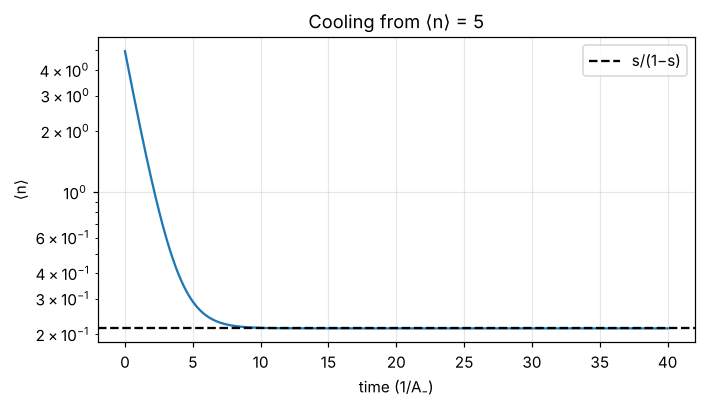

In [3]:
def dark_state(eta=0.1, asym=0.1, heat=2.0):
    e2 = eta**2
    s = (4 * e2 * heat + asym) / (e2 * heat + 1.0)
    n = s / (1 - s) if s < 1 else np.inf
    return dict(s=s, n_ss=n, ground_pct=100 / (n + 1) if s < 1 else 0)

gm = dark_state()
print(gm)

# integrate the rate equations from a thermal ⟨n⟩ = 5 and watch them reach the same steady state
nmax, s = 80, gm["s"]
n = np.arange(nmax); P = (5 / 6) ** n / 6; P /= P.sum()
Am, Ap, dt = 1.0, s, 0.01
mean = []
for step in range(4000):
    dP = np.zeros_like(P)
    dP[:-1] += Am * (n[1:]) * P[1:]; dP -= Am * n * P
    dP[1:] += Ap * n[1:] * P[:-1]; dP -= Ap * (n + 1) * P
    P += dt * dP
    mean.append((n * P).sum())
plt.plot(np.arange(len(mean)) * dt, mean); plt.axhline(gm["n_ss"], ls="--", c="k", label="s/(1−s)")
plt.yscale("log"); plt.xlabel("time (1/A₋)"); plt.ylabel("⟨n⟩"); plt.legend(); plt.title("Cooling from ⟨n⟩ = 5")

## 4. Sideband thermometry
In the Lamb–Dicke regime with a weak probe, red ∝ η²⟨n⟩ and blue ∝ η²(⟨n⟩+1), so the ratio R = red/blue gives ⟨n⟩ = R/(1−R) and the ground-state population P₀ = 1/(⟨n⟩+1) for a thermal state.

In [4]:
for R in (0.05, 0.2, 0.5):
    nb = R / (1 - R); print(f"R = {R}: ⟨n⟩ = {nb:.3f}, P0 = {1/(nb+1):.3f}")

R = 0.05: ⟨n⟩ = 0.053, P0 = 0.950
R = 0.2: ⟨n⟩ = 0.250, P0 = 0.800
R = 0.5: ⟨n⟩ = 1.000, P0 = 0.500

## 5. Check against the page

In [5]:
def check(ours, page, rel=0.006):
    """Compare our numbers with the values the web page shows at its default settings."""
    bad = []
    for k, shown in page.items():
        v = ours[k]
        ok = abs(v - shown) <= rel * abs(shown) + 1e-12 or abs(v - shown) <= 0.5 * 10 ** -DECIMALS.get(k, 99)
        print(f"{k:>12}: notebook {v:<12.4g} page {shown:<10g} {'OK' if ok else 'MISMATCH'}")
        if not ok: bad.append(k)
    assert not bad, f"differs from the page: {bad}"
    print("All values match the page.")

ours = dict(x0_nm=ld["x0_nm"], eta=ld["eta"], recoil=ld["Er_over_hnu"], n_doppler=sb["n_doppler"], s=gm["s"], n_ss=gm["n_ss"], ground=gm["ground_pct"])
DECIMALS = dict(x0_nm=2, eta=4, recoil=3, n_doppler=3, s=4, n_ss=4, ground=1)
page = dict(x0_nm=24.10, eta=0.1942, recoil=0.038, n_doppler=29.825, s=0.1765, n_ss=0.2143, ground=82.4)
check(ours, page)

       x0_nm: notebook 24.1         page 24.1       OK
         eta: notebook 0.1942       page 0.1942     OK
      recoil: notebook 0.0377       page 0.038      OK
   n_doppler: notebook 29.82        page 29.825     OK
           s: notebook 0.1765       page 0.1765     OK
        n_ss: notebook 0.2143       page 0.2143     OK
      ground: notebook 82.35        page 82.4       OK
All values match the page.